# Phase 4 EDA ? Stage 1: structure, roles and data quality

Local input: `data/processed/patch_model_eligible_v1.parquet`. This notebook does not change eligibility, splits or data. No models or transformations are fitted.

**Test lock:** `nbr_5_mean` is never loaded for test rows. Metadata/schema inspection may include its column name/type, but no test target values, missingness, ranges or plots are computed. Test analysis below uses only the approved primary predictors plus necessary identity/split diagnostics. Retrospective QA is inspected only on train/validation. Later distribution and relationship analyses are placeholders.

In [10]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from IPython.display import display

ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
DATA = ROOT / "data/processed/patch_model_eligible_v1.parquet"
ROLE_FILE = ROOT / "data/processed/bigquery_ca175_tile1_v1/roles.json"
roles = json.loads(ROLE_FILE.read_text())
target = roles["target"]
assert target == "nbr_5_mean"
schema = pq.read_schema(DATA)
all_columns = schema.names
# Read all non-target columns, but prohibit unrestricted describe/head on this frame.
# Test QA values are not analyzed; only the explicit test_inputs view is used below.
data = pd.read_parquet(DATA, columns=[c for c in all_columns if c != target])
# Predicate filtering prevents exposing any test target in a pandas DataFrame.
y_dev = pd.read_parquet(DATA, columns=["patch_id", "split", target],
                        filters=[("split", "in", ["train", "validation"])])
assert set(y_dev.split) <= {"train", "validation"}
assert target not in data.columns
print(f"Source schema: {len(data):,} rows x {len(all_columns)} columns; test target withheld.")

Source schema: 111,257 rows x 129 columns; test target withheld.


## 1. Structural validation and frozen chronological splits
These checks use identifiers, dates, split assignments and patch geometry metadata?not test outcomes. Patch IDs must be unique; every fire must belong to one split. No automatic repair or deduplication is performed.

In [11]:
split_order = ["train", "validation", "test"]
counts = data.groupby("split").agg(patches=("patch_id", "size"), fires=("fire_id", "nunique")).reindex(split_order)
expected_counts = pd.DataFrame({"patches": [61090,19561,30606], "fires": [78,36,37]}, index=split_order)
pd.testing.assert_frame_equal(counts, expected_counts.rename_axis("split"))
assert data.shape[0] == 111257 and len(all_columns) == 129
assert data.fire_id.nunique() == 151
assert data[["patch_id", "fire_id", "split"]].notna().all().all()
assert data.patch_id.is_unique and data.groupby("fire_id").split.nunique().eq(1).all()
assert data.fire_year.between(2015,2020).all()
expected_split = np.select([data.fire_year.le(2017), data.fire_year.le(2019)], ["train", "validation"], default="test")
assert (data.split == expected_split).all()
assert data.groupby("fire_id").fire_year.nunique().eq(1).all()
assert (data.season1_year == data.fire_year + 1).all() and (data.season5_year == data.fire_year + 5).all()
assert np.allclose(data.patch_area_m2, 8100)
assert data.eligibility_status.eq("eligible_v1").all()
assert data.patch_id.eq(data.fire_id + "_r" + data.grid_row.astype(str) + "_c" + data.grid_col.astype(str)).all()
assert data.batch_id.eq("r" + (data.grid_row // 120).astype(str) + "_c" + (data.grid_col // 120).astype(str)).all()
assert not y_dev.patch_id.duplicated().any()
assert set(y_dev.patch_id) == set(data.loc[data.split != "test", "patch_id"])
display(counts)
print("PASS: unique patch IDs, 151 fire groups, frozen splits, canonical area and tile IDs.")

,patches,fires
split,,
train,61090,78
validation,19561,36
test,30606,37


PASS: unique patch IDs, 151 fire groups, frozen splits, canonical area and tile IDs.


## 2. Column roles: explicit and exhaustive
Use the saved production `roles.json`, cross-checked against `pipeline.dataset_roles()`. The metadata allowlist is the explicit metadata set in that function, not an inference from numeric dtype. Any unknown, overlap or role drift is reported and stops this stage.

Some operational fields (`batch_id`, `patch_area_m2`, `eligibility_status`) are classified as QA by the existing role function; retain that convention and annotate it rather than silently relabeling them. Early predictors are a subset of primary predictors, not a separate overlapping top-level role. Integer-valued EVT is categorical, not a continuous number.

In [12]:
from wildfire_recovery_forecasting.pipeline import dataset_roles
current_roles = dataset_roles(all_columns)  # Pure role lookup: no EE initialization/evaluation.
metadata = {"patch_id", "fire_id", "fire_name", "ignition_date", "fire_year", "split",
            "grid_row", "grid_col", "source_dataset", "landfire_condition_year", "landfire_version",
            "last_fully_prefire_growing_season_year", "prefire_search_start_year",
            "prefire_search_end_year", "season1_year", "season5_year"}
groups = {"predictor": set(roles["predictors"]), "target": {target},
          "metadata/identifier": metadata & set(all_columns), "QA": set(roles["qa"])}
role_matches = {c: [r for r, cols in groups.items() if c in cols] for c in all_columns}
role_problems = {c: matches for c, matches in role_matches.items() if len(matches) != 1}
missing_declared = (groups["predictor"] | groups["target"] | groups["QA"]) - set(all_columns)
role_drift = {r: sorted(set(roles[r]) ^ set(current_roles[r])) for r in ("predictors", "early_predictors", "qa")}
print("Unmapped/conflicting columns:", role_problems, "Missing declared:", sorted(missing_declared))
print("Role drift:", {r: values for r, values in role_drift.items() if values})
assert not role_problems and not missing_declared and not any(role_drift.values())
assert current_roles["target"] == target
predictors = roles["predictors"]
assert set(roles["early_predictors"]) <= set(predictors)
assert not any(c.startswith(("lcms_", "season5_", "nbr_5", "reburn_", "prior_fire_")) for c in predictors)
column_catalog = pd.DataFrame({"column": all_columns,
    "role": [role_matches[c][0] for c in all_columns],
    "parquet_dtype": [str(schema.field(c).type) for c in all_columns],
    "early_predictor": [c in roles["early_predictors"] for c in all_columns]})
display(column_catalog.groupby("role").size().rename("columns").to_frame())
display(column_catalog.groupby(["role", "parquet_dtype"]).size().rename("columns").to_frame())
print("Full 129-row catalog is available as column_catalog; not dumped here.")
dev = data.loc[data.split.isin(["train", "validation"])].merge(
    y_dev[["patch_id", target]], on="patch_id", how="left", validate="one_to_one")
test_inputs = data.loc[data.split.eq("test"), predictors].copy()
assert target not in test_inputs

Unmapped/conflicting columns: {} Missing declared: []
Role drift: {}


,columns
role,
QA,79
metadata/identifier,15
predictor,34
target,1


columns
role                parquet_dtype         
QA                  double              73
                    int64                2
                    string               4
metadata/identifier date32[day]          1
                    int64                9
                    string               5
predictor           double              32
                    int64                2
target              double               1

Full 129-row catalog is available as column_catalog; not dumped here.


## 3. Missingness by split and measurement support
Predictor missingness is allowed to be inspected in all splits. Target/retrospective-QA missingness is inspected only for training and validation. Test target missingness is deliberately **not calculated**.

Forest-supported measurements can be structurally missing when valid support is zero. Because these rows already require forest_fraction >= 0.50, widespread vegetation/terrain missingness would merit attention rather than being dismissed as nonforest. A missing measurement despite positive reported support is particularly concerning. We report associations, not inferred causal explanations. Zero observed MTBS overlap does not establish archive completeness.

In [13]:
missing_by_split = pd.DataFrame({s: data.loc[data.split.eq(s), predictors].isna().mean()*100 for s in split_order})
missing_by_split["max_pct"] = missing_by_split.max(axis=1)
missing_by_split = missing_by_split.sort_values(["max_pct"], ascending=False, kind="stable")
display(missing_by_split.head(12).round(3))
print("Predictors with any missing values:", int(missing_by_split.max_pct.gt(0).sum()))
dev_missing = dev.isna().mean().mul(100).sort_values(ascending=False)
display(dev_missing[dev_missing.gt(0)].head(15).rename("train_validation_missing_pct").to_frame())
display(dev.groupby("split")[target].apply(lambda s: s.isna().mean()*100).rename("target_missing_pct").to_frame())

support_fields = {"tree_cover_mean":"tree_cover_valid_fraction", "tree_height_mean":"tree_height_valid_fraction",
    "elevation_mean":"elevation_valid_fraction", "slope_mean":"slope_valid_fraction",
    "northness_mean":"aspect_valid_fraction", "eastness_mean":"aspect_valid_fraction",
    "dominant_evt":"evt_valid_fraction", "nbr_pre_mean":"nbr_pre_valid_fraction", "nbr_1_mean":"nbr_1_valid_fraction"}
support_rows=[]
for measurement, support in support_fields.items():
    missing = dev[measurement].isna()
    support_rows.append({"predictor":measurement,"missing_rows":int(missing.sum()),
        "missing_zero_support":int((missing & dev[support].eq(0)).sum()),
        "missing_positive_support":int((missing & dev[support].gt(0)).sum()),
        "missing_unknown_support":int((missing & dev[support].isna()).sum())})
support_audit=pd.DataFrame(support_rows).set_index("predictor")
display(support_audit)
print("Support attribution above is train/validation only; test uses approved input columns only.")
display(dev[["prior_fire_fraction_10yr_coverage_status", "reburn_fraction_coverage_status"]].apply(lambda s: s.value_counts()).fillna(0))
qa_missing_by_split = pd.DataFrame({s: dev.loc[dev.split.eq(s), roles["qa"]].isna().mean()*100 for s in ["train", "validation"]})
print("QA columns with missing values in train/validation:", int(qa_missing_by_split.max(axis=1).gt(0).sum()))
display(qa_missing_by_split.loc[qa_missing_by_split.max(axis=1).gt(0)].head(10))


,train,validation,test,max_pct
slope_mean,10.327,0.562,31.317,31.317
northness_mean,10.327,0.562,31.317,31.317
eastness_mean,10.327,0.562,31.317,31.317
elevation_mean,10.311,0.547,31.295,31.295
nbr_pre_mean,0.000,0.000,0.000,0.000
dominant_evt,0.000,0.000,0.000,0.000
dominant_evt_fraction,0.000,0.000,0.000,0.000
tree_cover_mean,0.000,0.000,0.000,0.000
tree_height_mean,0.000,0.000,0.000,0.000
fire_size_acres,0.000,0.000,0.000,0.000


Predictors with any missing values: 4


,train_validation_missing_pct
eastness_mean,7.958984
northness_mean,7.958984
slope_mean,7.958984
elevation_mean,7.942865


,target_missing_pct
split,
train,0.0
validation,0.0


,missing_rows,missing_zero_support,missing_positive_support,missing_unknown_support
predictor,,,,
tree_cover_mean,0,0,0,0
tree_height_mean,0,0,0,0
elevation_mean,6406,6406,0,0
slope_mean,6419,6419,0,0
northness_mean,6419,6419,0,0
eastness_mean,6419,6419,0,0
dominant_evt,0,0,0,0
nbr_pre_mean,0,0,0,0
nbr_1_mean,0,0,0,0


Support attribution above is train/validation only; test uses approved input columns only.


,prior_fire_fraction_10yr_coverage_status,reburn_fraction_coverage_status
unverified,80651,80651


QA columns with missing values in train/validation: 0


,train,validation


## 4. Basic numerical quality (not distribution-comparison EDA)
The complete range tables stay in memory; output is limited to key fields and anomalies. Train/validation can include target and QA; test uses only approved predictors. Infinity is invalid numerical data. Range flags are review prompts, not new exclusion rules: NBR outside [-1,1] is possible after scaled reflectance and is not automatically clipped or deleted. Negative temperature, elevation, anomalies and NBR drop are not intrinsically erroneous.

In [14]:
def numeric_quality(frame):
    numeric = frame.select_dtypes(include="number")
    return pd.DataFrame({"dtype":numeric.dtypes.astype(str),
        "missing_pct":numeric.isna().mean()*100, "min":numeric.min(), "max":numeric.max(),
        "infinite_rows":np.isinf(numeric).sum()})

quality_dev = numeric_quality(dev)
quality_test_inputs = numeric_quality(test_inputs)
key_fields = ["nbr_pre_mean", "nbr_1_mean", target, "nbr_drop_patch", "tree_cover_mean", "tree_height_mean",
              "elevation_mean", "slope_mean", "hist_prcp_mm", "hist_s1_vpd_kpa"]
display(quality_dev.loc[key_fields].round(4))
print("Infinite values (train/validation numeric fields):", int(quality_dev.infinite_rows.sum()))
print("Infinite values (test predictors only):", int(quality_test_inputs.infinite_rows.sum()))

# Common numerical support/range checks; no post-cutoff QA on test rows.
suspicious=[]
for scope, frame in [("train_validation", dev), ("test_inputs_only", test_inputs)]:
    def flag(name, invalid, note):
        suspicious.append({"scope":scope,"check":name,"rows":int(pd.Series(invalid).fillna(False).sum()),"interpretation":note})
    for c in frame.select_dtypes(include="number"):
        if "fraction" in c:
            flag(c+" bounds", (frame[c]<-1e-6)|(frame[c]>1+1e-6), "Outside numerical [0,1] tolerance")
    for c, low, high in [("tree_cover_mean",0,100),("tree_height_mean",1,99),
                          ("slope_mean",0,90),("northness_mean",-1,1),("eastness_mean",-1,1),
                          ("ignition_month",1,12)]:
        flag(c+" bounds", (frame[c]<low-1e-6)|(frame[c]>high+1e-6), "Outside physical/decoded range")
    for c in ["hist_prcp_mm","pre_s1_prcp_mm","hist_s1_vpd_kpa","pre_s1_vpd_kpa"]:
        flag(c+" negative",frame[c]<-1e-9,"Nonnegative absolute climate quantity expected")
    flag("EVT noninteger",frame.dominant_evt.notna() & frame.dominant_evt.mod(1).ne(0),"EVT is a class code")
    flag("nonpositive acreage",frame.fire_size_acres<=0,"Fire size must be positive")
    flag("drop inconsistency",~np.isclose(frame.nbr_drop_patch,frame.nbr_pre_mean-frame.nbr_1_mean,equal_nan=True,atol=1e-12,rtol=1e-9),"Approved independently supported patch difference")
    for c in ["nbr_pre_mean","nbr_1_mean"] + ([target] if scope=="train_validation" else []):
        flag(c+" outside nominal range",frame[c].abs()>1,"Review reflectance/ratio behavior; not automatic exclusion")
suspicious_values=pd.DataFrame(suspicious)
display(suspicious_values.loc[suspicious_values.rows.gt(0)])
print(f"{len(suspicious_values)} basic range/consistency checks; {int(suspicious_values.rows.gt(0).sum())} checks flagged rows.")
print("No values were changed, clipped, imputed or removed.")

,dtype,missing_pct,min,max,infinite_rows
nbr_pre_mean,float64,0.0000,-0.1753,0.8543,0
nbr_1_mean,float64,0.0000,-0.4243,0.8059,0
nbr_5_mean,float64,0.0000,-0.2728,0.8132,0
nbr_drop_patch,float64,0.0000,-0.2964,1.2099,0
tree_cover_mean,float64,0.0000,15.0000,91.6696,0
tree_height_mean,float64,0.0000,8.0000,11.7784,0
elevation_mean,float64,7.9429,48.5441,3081.7372,0
slope_mean,float64,7.9590,0.0000,59.4568,0
hist_prcp_mm,float64,0.0000,1.9270,160.3740,0
hist_s1_vpd_kpa,float64,0.0000,0.7407,3.0492,0


Infinite values (train/validation numeric fields): 0
Infinite values (test predictors only): 0


,scope,check,rows,interpretation


94 basic range/consistency checks; 0 checks flagged rows.
No values were changed, clipped, imputed or removed.


## 5. Categorical predictors and preprocessing candidates
`dominant_evt` is a nominal vegetation class even when stored numerically; arithmetic scaling of its IDs would be inappropriate. `ignition_month` is a discrete seasonal input (a later choice between categorical/cyclic representation). Fire IDs/names, split, baseline version, batch IDs and coverage statuses are metadata/QA, not categorical model predictors.

Any future imputation, scaling, category vocabulary, rare-category grouping or encoding must be fitted on **training data only**. Validation/test unknown categories need an explicit handling policy. No transformations are fitted here. Constant training inputs are reported as candidates for review, not dropped; NBR drop is deterministically related to NBRpre and NBR1 and may matter for linear-model collinearity.

In [15]:
train_inputs=data.loc[data.split.eq("train"),predictors]
categorical_summary=pd.DataFrame({"semantic_type":["nominal vegetation class","discrete seasonal input"],
    "train_levels":[train_inputs.dominant_evt.nunique(),train_inputs.ignition_month.nunique()],
    "train_missing_pct":[train_inputs.dominant_evt.isna().mean()*100,train_inputs.ignition_month.isna().mean()*100]},
    index=["dominant_evt","ignition_month"])
display(categorical_summary)
constant_train=train_inputs.nunique(dropna=True)
print("Constant/all-missing training predictors:",constant_train[constant_train.le(1)].to_dict())
print("No preprocessing or model fitting performed. Test target remains withheld.")

,semantic_type,train_levels,train_missing_pct
dominant_evt,nominal vegetation class,44,0.0
ignition_month,discrete seasonal input,10,0.0


Constant/all-missing training predictors: {}
No preprocessing or model fitting performed. Test target remains withheld.


## 6. Stage-1 findings and boundaries
**Executed findings:** 111,257 rows, 129 columns, 151 fires; 34 predictors, 1 target, 15 metadata/identifier columns and 79 QA columns, with no unknown/conflicting roles. No duplicate patch IDs, split inconsistencies, infinities or flags in the 94 basic range/consistency checks.

Only four predictors have missing values: elevation, slope, northness and eastness. Slope/northness/eastness missingness is 10.327% train, 0.562% validation and 31.317% test; elevation is 10.311%, 0.547% and 31.295%. This is an important input-availability concern, not evidence of test-target shift. In train/validation, these missing measurements consistently have zero corresponding terrain-valid support (6,406 elevation rows; 6,419 slope/aspect rows), rather than positive support paired with missing measurements. The upstream reason is **not established** by this check; do not blame forest absence, impute zero, alter eligibility or repair the pipeline here. Test support QA was not examined. All other predictors have zero missingness in each split. Train/validation target missingness is zero; test target missingness was not computed.

The categorical input audit finds 44 training EVT classes and 10 training ignition-month values, with no constant/all-missing training predictors. These are preprocessing considerations, not fitted encoders.

The executed tables above are the reproducible findings. Read missingness alongside support QA; absence of nulls does not establish complete MTBS history or perfect remote-sensing observation. Missingness and range screens do not measure predictive performance. Retrospective eligibility conditions this historical cohort and must not be treated as input features.

The primary and early-ablation lists remain unchanged. Later model fitting must use the eligible dataset and fire-grouped chronological assignments, not the candidate-stage SQL projections alone.

## 7. Later: distribution comparisons (placeholder)
Train/validation and approved test-input distribution comparisons, including the **unmeasured 2020 distribution-shift concern**, belong to the next EDA stage. Keep the original 2015?2017 / 2018?2019 / 2020 split; no test target exploration or split redesign here.

## 8. Later: feature relationships (placeholder)
Feature relationships and training/validation target relationships will be considered later. No test target access, correlation plots, preprocessing fitting or model selection in Stage 1.

## Focused terrain missingness diagnostic
Reuses Stage 1's established counts; this section executes independently without rerunning earlier EDA. Reads only the four approved terrain predictors and fire/year/split identifiers for all rows. Forest/support/geographic comparisons are restricted to train/validation through a filtered Parquet read. No NBR5 values or test retrospective QA are loaded. All rates below describe the **eligible** cohort; missingness in excluded patches is not assessed.

In [16]:
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display
ROOT = Path.cwd() if (Path.cwd()/"pyproject.toml").exists() else Path.cwd().parent
DATA = ROOT/"data/processed/patch_model_eligible_v1.parquet"
terrain_names = ["elevation_mean", "slope_mean", "northness_mean", "eastness_mean"]
terrain_only = pd.read_parquet(DATA, columns=["fire_id", "fire_year", "split", *terrain_names])
for c in terrain_names:
    terrain_only[c+"_missing"] = terrain_only[c].isna()
assert terrain_only.northness_mean_missing.equals(terrain_only.eastness_mean_missing)
assert terrain_only.slope_mean_missing.equals(terrain_only.northness_mean_missing)
# Full per-fire table retained in memory; concise output shows the largest contributors.
def terrain_summary(keys):
    grouped = terrain_only.groupby(keys, observed=True)
    result = grouped.size().rename("patches").to_frame()
    for c in terrain_names:
        short = c.removesuffix("_mean")
        result[short+"_missing"] = grouped[c+"_missing"].sum()
        result[short+"_pct"] = 100*result[short+"_missing"]/result.patches
    return result
by_year = terrain_summary(["split", "fire_year"])
by_fire = terrain_summary(["fire_id", "fire_year", "split"])
by_fire["extent"] = np.select([by_fire.slope_missing.eq(0), by_fire.slope_missing.eq(by_fire.patches)], ["none", "entire eligible fire"], default="partial eligible fire")
by_fire["share_of_all_missing_slope_pct"] = 100*by_fire.slope_missing/by_fire.slope_missing.sum()
display(by_year[["patches","elevation_missing","elevation_pct","slope_missing","slope_pct"]].round(3))
print("Slope, northness and eastness missingness masks are identical.")
display(by_fire.sort_values("slope_missing", ascending=False)[["patches","elevation_missing","slope_missing","slope_pct","extent"]].head(12).round(3))
display(by_fire.loc[by_fire.extent.eq("entire eligible fire"), ["patches","elevation_missing","slope_missing"]])
display(by_fire.reset_index().groupby(["split", "extent"]).agg(fires=("fire_id","size"),patches=("patches","sum"),missing_slope=("slope_missing","sum")))
print("Entire fire means all its eligible rows in the selected tile, not its complete perimeter.")
print("Rows missing slope with elevation present:", int((terrain_only.slope_mean_missing & ~terrain_only.elevation_mean_missing).sum()))


patches  elevation_missing  elevation_pct  \
split      fire_year                                              
test       2020         30606               9578         31.295   
train      2015         24327                  0          0.000   
           2016         11226               1018          9.068   
           2017         25537               5281         20.680   
validation 2018         13124                 34          0.259   
           2019          6437                 73          1.134   

                      slope_missing  slope_pct  
split      fire_year                            
test       2020                9585     31.317  
train      2015                   0      0.000  
           2016                1018      9.068  
           2017                5291     20.719  
validation 2018                  34      0.259  
           2019                  76      1.181

Slope, northness and eastness missingness masks are identical.


,,,patches,elevation_missing,slope_missing,slope_pct,extent
fire_id,fire_year,split,,,,,
CA4009112093120200817,2020,test,4116,3980,3980,96.696,partial eligible fire
CA4143512316220170626,2017,train,2872,2522,2525,87.918,partial eligible fire
CA3867312307820200817,2020,test,3455,2323,2325,67.294,partial eligible fire
CA3589912026320170710,2017,train,1083,1068,1069,98.707,partial eligible fire
CA3453012005420160615,2016,train,1018,1018,1018,100.000,entire eligible fire
CA3801812283920200818,2020,test,978,934,935,95.603,partial eligible fire
CA4118512343320200728,2020,test,954,921,922,96.646,partial eligible fire
CA3702412151420200705,2020,test,829,803,804,96.984,partial eligible fire
CA4130712105620170725,2017,train,1811,607,610,33.683,partial eligible fire


,,,patches,elevation_missing,slope_missing
fire_id,fire_year,split,,,
CA3400611730620170430,2017,train,1,1,1
CA3453012005420160615,2016,train,1018,1018,1018
CA3606611745820200728,2020,test,101,101,101


fires  patches  missing_slope
split      extent                                              
test       entire eligible fire       1      101            101
           none                      26    16658              0
           partial eligible fire     10    13847           9484
train      entire eligible fire       2     1019           1019
           none                      70    51650              0
           partial eligible fire      6     8421           5290
validation none                      33    18733              0
           partial eligible fire      3      828            110

Entire fire means all its eligible rows in the selected tile, not its complete perimeter.
Rows missing slope with elevation present: 20


### Train/validation support, forest fraction and geographic metadata
Forest fraction is measured on the EVC reduction grid; terrain validity uses its own source grid and forest-support denominator. Positive EVC forest fraction therefore does not prove valid DEM coverage. We compare forest occupancy bins and within-fire forest means, avoiding a causal claim from pooled averages. Grid indices are EPSG:5070 lattice coordinates, not latitude/longitude; geographic summaries are descriptive, not fitted predictors.

In [17]:
support_names = ["elevation_valid_fraction", "slope_valid_fraction", "aspect_valid_fraction"]
terrain_dev = pd.read_parquet(DATA, columns=["fire_id", "fire_year", "split", "grid_row", "grid_col", "batch_id", "forest_fraction", *terrain_names, *support_names], filters=[("split", "in", ["train", "validation"])])
assert not terrain_dev.split.eq("test").any()
terrain_dev["missing_slope"] = terrain_dev.slope_mean.isna()
comparison = terrain_dev.groupby("missing_slope").agg(
    patches=("fire_id","size"), fires=("fire_id","nunique"),
    forest_min=("forest_fraction","min"),forest_median=("forest_fraction","median"),forest_mean=("forest_fraction","mean"),forest_max=("forest_fraction","max"),
    elevation_support_mean=("elevation_valid_fraction","mean"),slope_support_mean=("slope_valid_fraction","mean"),aspect_support_mean=("aspect_valid_fraction","mean"),
    row_min=("grid_row","min"),row_max=("grid_row","max"),col_min=("grid_col","min"),col_max=("grid_col","max"))
display(comparison.round(4))
forest_bins = pd.cut(terrain_dev.forest_fraction, [.499999, .6, .8, 1.000001], labels=["0.50-0.60",">0.60-0.80",">0.80-1.00"])
forest_rates = terrain_dev.groupby(forest_bins, observed=True).agg(patches=("fire_id","size"),missing=("missing_slope","sum"),missing_pct=("missing_slope",lambda s:100*s.mean()))
display(forest_rates.round(3))
within_fire = terrain_dev.groupby(["fire_id","missing_slope"]).forest_fraction.mean().unstack()
within_fire.columns = ["terrain_present_forest_mean" if not c else "terrain_missing_forest_mean" for c in within_fire.columns]
within_fire = within_fire.dropna()
within_fire["difference_missing_minus_present"] = within_fire.terrain_missing_forest_mean-within_fire.terrain_present_forest_mean
print("Fires with both available and missing terrain:",len(within_fire))
display(within_fire.round(4).head(12))
# All these geographic/QA associations use development rows only.
geo_dev = terrain_dev.groupby(["fire_id","fire_year"]).agg(patches=("fire_id","size"),missing=("missing_slope","sum"),grid_row_min=("grid_row","min"),grid_row_max=("grid_row","max"),grid_col_min=("grid_col","min"),grid_col_max=("grid_col","max"))
display(geo_dev.loc[geo_dev.missing.gt(0)].sort_values("missing",ascending=False).head(8))
for measurement, support in [("elevation_mean","elevation_valid_fraction"),("slope_mean","slope_valid_fraction"),("northness_mean","aspect_valid_fraction"),("eastness_mean","aspect_valid_fraction")]:
    absent=terrain_dev[measurement].isna()
    print(measurement, {"missing":int(absent.sum()),"zero_support":int((absent & terrain_dev[support].eq(0)).sum()),"positive_support":int((absent & terrain_dev[support].gt(0)).sum()),"unknown_support":int((absent & terrain_dev[support].isna()).sum())})


,patches,fires,forest_min,forest_median,forest_mean,forest_max,elevation_support_mean,slope_support_mean,aspect_support_mean,row_min,row_max,col_min,col_max
missing_slope,,,,,,,,,,,,,
False,74232,112,0.5,1.0000,0.9204,1.0,0.999,0.9988,0.9988,14057,27080,-25558,-20882
True,6419,11,0.5,0.9725,0.8782,1.0,0.000,0.0000,0.0000,15928,26364,-25092,-21515


,patches,missing,missing_pct
forest_fraction,,,
0.50-0.60,4830,598,12.381
>0.60-0.80,9452,1124,11.892
>0.80-1.00,66369,4697,7.077


Fires with both available and missing terrain: 9


,terrain_present_forest_mean,terrain_missing_forest_mean,difference_missing_minus_present
fire_id,,,
CA3456711995220170708,0.8862,0.8603,-0.0259
CA3589912026320170710,0.7048,0.8052,0.1005
CA3703411834520190904,0.8928,0.7472,-0.1456
CA3805012095020180629,0.6715,0.6230,-0.0486
CA3900312269020171009,0.7767,0.6117,-0.1650
CA3988012002520190824,0.6080,0.6091,0.0011
CA4083912297820170808,0.9497,0.9240,-0.0257
CA4130712105620170725,0.9626,0.9353,-0.0273
CA4143512316220170626,0.9558,0.9410,-0.0148


,,patches,missing,grid_row_min,grid_row_max,grid_col_min,grid_col_max
fire_id,fire_year,,,,,,
CA4143512316220170626,2017,2872,2525,26280,26364,-24600,-24497
CA3589912026320170710,2017,1083,1069,19080,19118,-23987,-23886
CA3453012005420160615,2016,1018,1018,17160,17219,-24103,-24041
CA4130712105620170725,2017,1811,610,25508,25559,-22870,-22801
CA3456711995220170708,2017,1809,574,17161,17235,-24061,-24001
CA4083912297820170808,2017,714,507,25539,25559,-24799,-24731
CA3703411834520190904,2019,712,65,19763,19799,-21720,-21679
CA3805012095020180629,2018,40,34,21600,21681,-23805,-23761


elevation_mean {'missing': 6406, 'zero_support': 6406, 'positive_support': 0, 'unknown_support': 0}
slope_mean {'missing': 6419, 'zero_support': 6419, 'positive_support': 0, 'unknown_support': 0}
northness_mean {'missing': 6419, 'zero_support': 6419, 'positive_support': 0, 'unknown_support': 0}
eastness_mean {'missing': 6419, 'zero_support': 6419, 'positive_support': 0, 'unknown_support': 0}


### Code trace, evidence and decision

**Confirmed current behavior (local source inspection):**

1. `terrain.build_terrain_images()` selects `ee.ImageCollection("USGS/3DEP/10m_collection").filterBounds(geometry).first()`, then selects elevation. The production caller supplies the patch-union bounding region. Intersecting that region does **not** guarantee that the first image covers every patch. There is no mosaic or explicit multi-image coverage check here. The chosen image/footprint was not inspected remotely in this task.
2. `ee.Terrain.products(elevation)` derives slope/aspect before clipping; northness/eastness inherit aspect masks. Derivative neighborhoods can lose edge support even where elevation exists. Only 20 eligible rows overall have missing slope but present elevation; that small difference does not explain the broad elevation gaps.
3. `landfire.build_landfire_images()` supplies EVC tree support; `reductions.build_terrain_product()` applies `updateMask(forest)` independently to each terrain measurement. It also reduces the forest support image on the selected DEM projection. EVC forest_fraction itself uses the EVC grid, not this DEM grid.
4. `build_area_sums()` exports masked value-times-pixel-area sums, corresponding valid area, and forest `support_sum`. `manual_prepare_bigquery.area_fields(..., support=True)` returns a NULL mean when measurement area is zero/missing and computes validity as valid area divided by positive forest support, otherwise zero. Northness validity becomes `aspect_valid_fraction`. A zero final validity cannot alone distinguish unavailable measurement area from unavailable support denominator; the final table does not retain all raw sums/areas. The observed missing/zero-support pairing is consistent with this code, not proof the upstream image selection was correct.

**Observed, not inferred:** 22 of 151 fires have some missing slope/aspect (8 train, 3 validation, 11 test); 3 are wholly missing within their eligible selected-tile subset. There are 16,004 missing slope/aspect rows and 15,984 missing elevation rows overall. Train/validation missing-slope patches have forest median 0.9725 and mean 0.8782, versus 1.0 and 0.9204 when present. Of 6,419 development missing-slope rows, 4,697 have forest_fraction >0.80. Within-fire forest differences have mixed signs. Forest fraction is associated with missingness in pooled bins, but **lack of forest does not explain it**. The development grid ranges place gaps in multiple selected tiles; they do not establish source boundaries or a specific geographic cause.

| Explanation | Evidence status |
|---|---|
| First selected 3DEP image covers only part of a requested tile, while other collection images might cover the rest | Strongest concrete implementation concern: `.first()` is confirmed, coverage consequence remains unverified. Development fires alone justify this concern. |
| Genuine DEM footprint/nodata coverage gaps | Plausible; cannot distinguish archive gaps from omitted images using final means/validity alone. |
| Derivative edge masks | Plausible for the 20 elevation-present/slope-missing rows; insufficient for most gaps. |
| Forest-mask/source-grid interaction | Plausible but unproven; EVC forest fraction does not guarantee DEM-grid valid support. No direct evidence of a CRS error. |
| BigQuery invented missing values or dropped rows | No positive evidence here: existing joins preserve IDs and SQL deliberately maps absent measurement area to NULL. Final fields alone cannot fully audit raw exports. |

**Decision: INVESTIGATE FURTHER ? possible source-selection correctness issue, not confirmed expected missingness.** Do not silently fix, mosaic, rerun exports or discard affected fires here. The narrow question, if separately authorized, is whether the existing selected DEM image covered a development tile versus other intersecting images; this is not a new feature or test-driven redesign. Other bounded EDA can proceed, but do not certify terrain as correct merely by imputing it.

**Modeling implication:** test input missingness (31.317% slope/aspect versus 10.327% train and 0.562% validation) represents a substantial availability difference, not a measured target/performance shift. Keep all original chronological splits and test outcomes locked. If gaps are ultimately accepted, use an explicitly documented missing-value strategy fitted on training only (model-native missingness or train-fitted imputation, with any missingness indicators handled in the modeling stage); never zero-fill elevation or slope as a physical value. Imputation does not repair a source-coverage bug and may encode geography/source artifacts. No strategy is fitted or feature role changed in this investigation.

Only these new diagnostic cells were executed; Stage 1 was not rerun. No test NBR5, test terrain-support QA, or other test retrospective QA was loaded. No cloud operations or pipeline/data changes occurred.

## Stage 2 — Train/Validation/Test Distribution Comparison

In [19]:

# STEP 1A: Compare burn severity and fire characteristics
# Uses approved predictors only — never the test target.



terrain_cols = {
    "elevation_mean", "slope_mean",
    "northness_mean", "eastness_mean"
}

severity_cols = [
    c for c in predictors
    if c.startswith("mtbs_") and c.endswith("_fraction")
]

print("Burn-severity columns:")
print(severity_cols)

core_cols = [
    "fire_size_acres",
    "forest_fraction",
    "nbr_pre_mean",
    "nbr_1_mean",
    "nbr_drop_patch",
    "tree_cover_mean",
]

metrics = list(dict.fromkeys(
    [c for c in severity_cols + core_cols
     if c in predictors and c not in terrain_cols]
))

assert "nbr_5_mean" not in metrics

comparison = data[
    ["split", "fire_id", "fire_year"] + metrics
].copy()

# Patch-weighted: every patch contributes equally.
patch_means = (
    comparison.groupby("split")[metrics]
    .mean()
    .reindex(["train", "validation", "test"])
)

# Fire-weighted: average within each fire first,
# then give each fire equal weight.
per_fire = (
    comparison.groupby(["split", "fire_id"])[metrics]
    .mean()
    .reset_index()
)

fire_means = (
    per_fire.groupby("split")[metrics]
    .mean()
    .reindex(["train", "validation", "test"])
)

print("\nPATCH-WEIGHTED MEANS")
display(patch_means.T.round(3))

print("\nEQUAL-FIRE-WEIGHTED MEANS")
display(fire_means.T.round(3))

print("\nFIRES AND PATCHES BY YEAR")
display(
    comparison.groupby(["split", "fire_year"])
    .agg(
        patches=("fire_id", "size"),
        fires=("fire_id", "nunique")
    )
)


Burn-severity columns:
['mtbs_unburned_low_fraction', 'mtbs_low_fraction', 'mtbs_moderate_fraction', 'mtbs_high_fraction', 'mtbs_increased_greenness_fraction']

PATCH-WEIGHTED MEANS


split,train,validation,test
mtbs_unburned_low_fraction,0.089,0.093,0.063
mtbs_low_fraction,0.414,0.500,0.377
mtbs_moderate_fraction,0.313,0.282,0.315
mtbs_high_fraction,0.176,0.117,0.236
mtbs_increased_greenness_fraction,0.001,0.000,0.000
fire_size_acres,55144.380,59279.948,85253.100
nbr_pre_mean,0.471,0.438,0.456
nbr_1_mean,0.180,0.168,0.081
nbr_drop_patch,0.292,0.270,0.375
tree_cover_mean,50.708,47.016,46.000



EQUAL-FIRE-WEIGHTED MEANS


split,train,validation,test
mtbs_unburned_low_fraction,0.097,0.098,0.075
mtbs_low_fraction,0.441,0.558,0.476
mtbs_moderate_fraction,0.310,0.258,0.314
mtbs_high_fraction,0.139,0.066,0.125
mtbs_increased_greenness_fraction,0.001,0.000,0.000
fire_size_acres,22104.936,25495.944,48740.541
nbr_pre_mean,0.366,0.293,0.336
nbr_1_mean,0.145,0.120,0.056
nbr_drop_patch,0.221,0.173,0.281
tree_cover_mean,45.010,38.945,38.877



FIRES AND PATCHES BY YEAR


patches  fires
split      fire_year                
test       2020         30606     37
train      2015         24327     23
           2016         11226     22
           2017         25537     33
validation 2018         13124     22
           2019          6437     14


MTBS_HIGH_FRACTION — FIRE-LEVEL DISTRIBUTION


,mean,median,minimum,maximum
split,,,,
train,0.139,0.090,0.0,0.764
validation,0.066,0.021,0.0,0.318
test,0.125,0.091,0.0,0.570


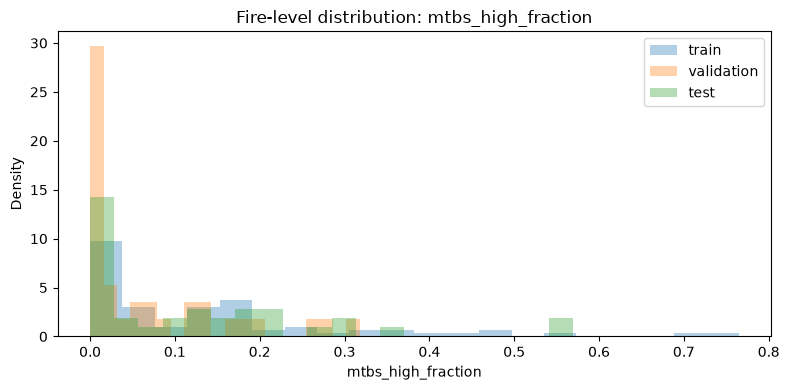


NBR_DROP_PATCH — FIRE-LEVEL DISTRIBUTION


,mean,median,minimum,maximum
split,,,,
train,0.221,0.236,-0.065,0.534
validation,0.173,0.204,-0.096,0.423
test,0.281,0.281,0.078,0.599


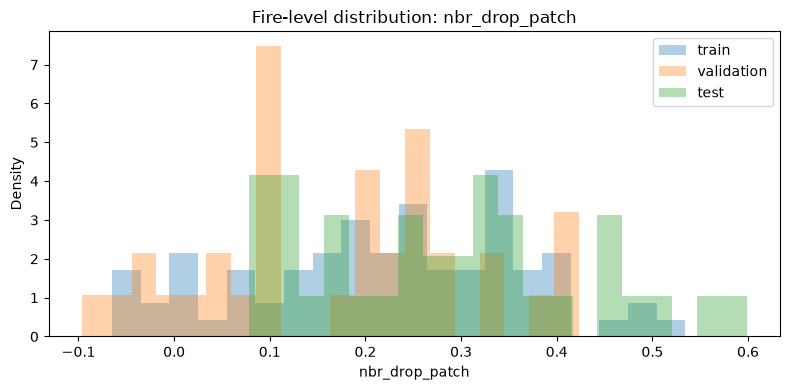


FIRE_SIZE_ACRES — FIRE-LEVEL DISTRIBUTION


,mean,median,minimum,maximum
split,,,,
train,22104.936,6319.5,1002.0,281982.0
validation,25495.944,3844.5,1250.0,233710.0
test,48740.541,9337.0,1242.0,405787.0


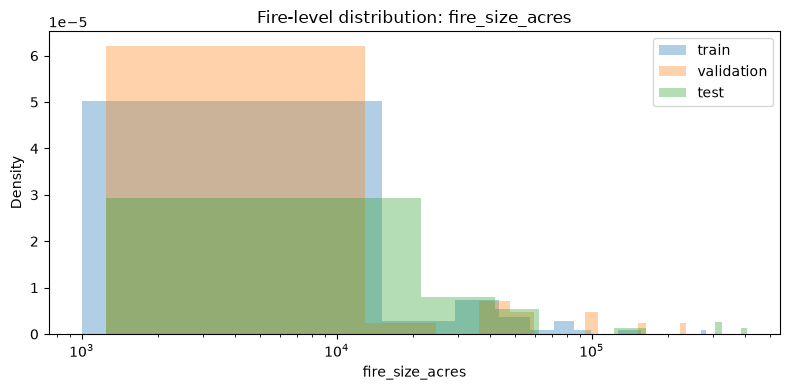

In [20]:

import matplotlib.pyplot as plt

split_order = ["train", "validation", "test"]

# Compare entire fires equally.
# Uses the per_fire table created in our previous cell.
for feature in [
    "mtbs_high_fraction",
    "nbr_drop_patch",
    "fire_size_acres",
]:
    print(f"\n{feature.upper()} — FIRE-LEVEL DISTRIBUTION")

    summary = (
        per_fire.groupby("split")[feature]
        .agg(
            mean="mean",
            median="median",
            minimum="min",
            maximum="max",
        )
        .reindex(split_order)
    )

    display(summary.round(3))

    plt.figure(figsize=(8, 4))

    for split in split_order:
        values = per_fire.loc[
            per_fire["split"] == split, feature
        ].dropna()

        plt.hist(
            values,
            bins=20,
            density=True,
            alpha=0.35,
            label=split,
        )

    if feature == "fire_size_acres":
        plt.xscale("log")

    plt.xlabel(feature)
    plt.ylabel("Density")
    plt.title(f"Fire-level distribution: {feature}")
    plt.legend()
    plt.tight_layout()
    plt.show()


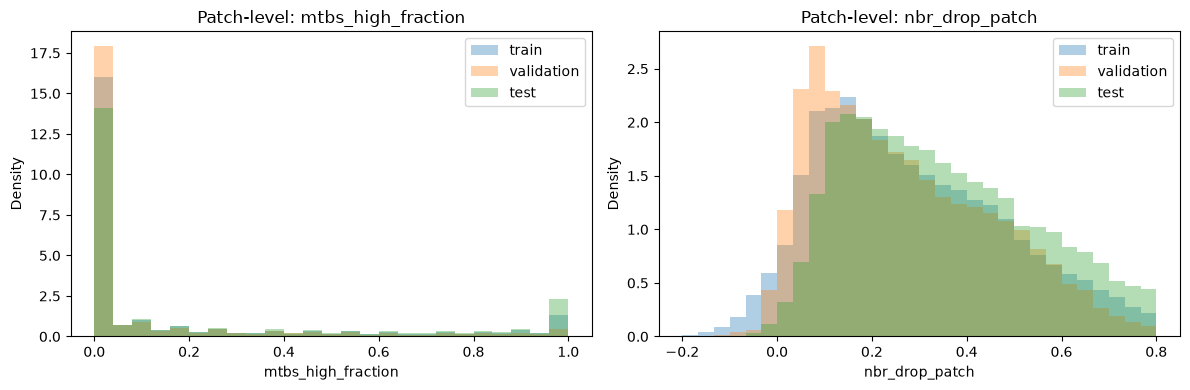

In [21]:

import numpy as np
import matplotlib.pyplot as plt

features = {
    "mtbs_high_fraction": np.linspace(0, 1, 26),
    "nbr_drop_patch": np.linspace(-0.2, 0.8, 31),
}

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, (feature, bins) in zip(axes, features.items()):
    for split in ["train", "validation", "test"]:
        values = comparison.loc[
            comparison["split"] == split, feature
        ].dropna()

        ax.hist(
            values,
            bins=bins,
            density=True,
            alpha=0.35,
            label=split
        )

    ax.set_title(f"Patch-level: {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Density")
    ax.legend()

plt.tight_layout()
plt.show()


In [22]:

for feature in ["mtbs_high_fraction", "nbr_drop_patch"]:
    print(f"\nPATCH-LEVEL: {feature.upper()}")
    display(
        comparison.groupby("split")[feature]
        .agg(["mean", "median", "min", "max"])
        .reindex(["train", "validation", "test"])
        .round(3)
    )



PATCH-LEVEL: MTBS_HIGH_FRACTION


,mean,median,min,max
split,,,,
train,0.176,0.0,0.0,1.0
validation,0.117,0.0,0.0,1.0
test,0.236,0.0,0.0,1.0



PATCH-LEVEL: NBR_DROP_PATCH


,mean,median,min,max
split,,,,
train,0.292,0.256,-0.296,1.210
validation,0.270,0.234,-0.194,1.139
test,0.375,0.334,-0.116,1.202


VEGETATION COMPARISON


split,patch_train,patch_validation,patch_test,fire_train,fire_validation,fire_test
tree_cover_mean,50.71,47.02,46.00,45.01,38.94,38.88
tree_height_mean,10.25,9.92,10.16,9.99,9.71,9.86


CLIMATE COMPARISON


split,patch_train,patch_validation,patch_test,fire_train,fire_validation,fire_test
hist_prcp_mm,39.14,49.50,34.57,31.78,34.03,27.79
hist_tmax_c,27.10,27.31,26.65,28.58,28.81,27.74
hist_tmin_c,11.34,11.74,11.15,12.30,12.90,12.68
hist_s1_vpd_kpa,1.84,1.84,1.78,2.07,2.11,1.97
pre_s1_prcp_mm,700.69,849.89,325.55,626.16,588.00,239.66
pre_s1_tmax_c,14.22,12.54,14.75,15.88,14.54,15.90
pre_s1_tmin_c,2.72,1.48,2.31,3.92,3.12,3.57
pre_s1_vpd_kpa,0.51,0.47,0.62,0.60,0.56,0.70
pre_s1_prcp_anom_mm,172.89,255.28,-300.69,187.84,174.85,-204.97
pre_s1_tmax_anom_c,0.05,-1.03,0.45,-0.11,-1.10,0.36


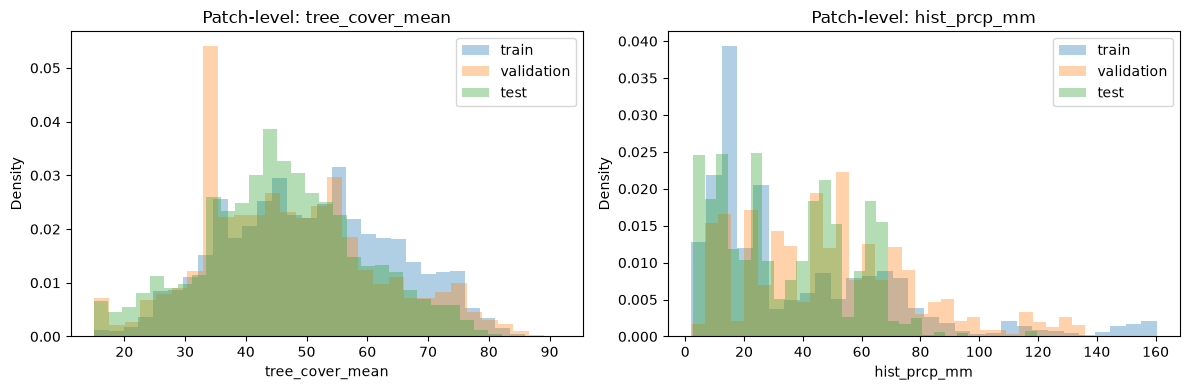

In [23]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

split_order = ["train", "validation", "test"]

# Only use approved predictors; exclude terrain under repair.
veg_cols = [
    c for c in ["tree_cover_mean", "tree_height_mean"]
    if c in predictors
]

climate_cols = [
    c for c in predictors
    if any(k in c for k in ["prcp", "tmax", "tmin", "vpd"])
]

cols = veg_cols + climate_cols
assert cols and all(c in predictors for c in cols)
assert "nbr_5_mean" not in cols

frame = data[["split", "fire_id"] + cols]

# Mean across all patches within each split.
patch_means = (
    frame.groupby("split")[cols]
    .mean()
    .reindex(split_order)
)

# Mean within each fire, then equal weight for each fire.
fire_means = (
    frame.groupby(["split", "fire_id"])[cols]
    .mean()
    .groupby(level="split")
    .mean()
    .reindex(split_order)
)

summary = pd.concat(
    [
        patch_means.T.add_prefix("patch_"),
        fire_means.T.add_prefix("fire_")
    ],
    axis=1
)

print("VEGETATION COMPARISON")
display(summary.loc[veg_cols].round(2))

print("CLIMATE COMPARISON")
display(summary.loc[climate_cols].round(2))

# Visualize two representative distributions.
plot_cols = [
    c for c in ["tree_cover_mean", "hist_prcp_mm"]
    if c in cols
]

fig, axes = plt.subplots(1, len(plot_cols),
                         figsize=(6 * len(plot_cols), 4))
axes = np.atleast_1d(axes)

for ax, col in zip(axes, plot_cols):
    for split in split_order:
        values = data.loc[data.split.eq(split), col].dropna()
        ax.hist(values, bins=30, density=True,
                alpha=0.35, label=split)

    ax.set_title(f"Patch-level: {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Density")
    ax.legend()

plt.tight_layout()
plt.show()


In [24]:

# Compare dominant vegetation classes across splits.
assert "dominant_evt" in predictors

top_evt = (
    data.loc[data.split.eq("train"), "dominant_evt"]
    .value_counts()
    .head(6)
    .index
)

evt = data[["split", "fire_id", "dominant_evt"]].copy()
evt["class_group"] = (
    evt["dominant_evt"]
    .where(evt["dominant_evt"].isin(top_evt), "Other")
    .astype(str)
)

# Percentage of selected patches in each class.
patch_evt = pd.crosstab(
    evt["split"], evt["class_group"], normalize="index"
).reindex(split_order) * 100

# Each fire contributes equally.
fire_evt = pd.crosstab(
    [evt["split"], evt["fire_id"]],
    evt["class_group"],
    normalize="index"
).groupby(level="split").mean().reindex(split_order) * 100

print("DOMINANT EVT — PATCH-WEIGHTED (%)")
display(patch_evt.round(1))

print("DOMINANT EVT — FIRE-WEIGHTED (%)")
display(fire_evt.round(1))


DOMINANT EVT — PATCH-WEIGHTED (%)


class_group,3014,3027,3028,3029,3032,3114,Other
split,,,,,,,
train,11.7,12.4,20.3,9.8,6.2,12.2,27.3
validation,4.6,15.1,18.8,5.7,9.2,6.6,40.2
test,9.1,4.1,19.8,4.6,7.5,7.9,47.0


DOMINANT EVT — FIRE-WEIGHTED (%)


class_group,3014,3027,3028,3029,3032,3114,Other
split,,,,,,,
train,12.1,10.3,13.7,6.8,3.0,17.2,37.0
validation,7.2,6.5,9.7,6.2,4.9,16.5,49.1
test,9.8,1.9,5.8,2.0,6.4,16.8,57.4


In [25]:

import pandas as pd

features = [
    "pre_s1_prcp_anom_mm",
    "s1_vpd_anom_kpa",
    "mtbs_high_fraction",
]

assert all(c in predictors for c in features)

train_x = data.loc[data["split"] == "train", features]
test_x = data.loc[data["split"] == "test", features]

rows = []

for col in features:
    tr = train_x[col].dropna()
    te = test_x[col].dropna()

    q01, q10, q90, q99 = tr.quantile([.01, .10, .90, .99])

    rows.append({
        "feature": col,
        "train_min": tr.min(),
        "train_p01": q01,
        "train_p10": q10,
        "train_p90": q90,
        "train_p99": q99,
        "train_max": tr.max(),
        "test_median": te.median(),
        "test_below_train_p01_%": 100 * (te < q01).mean(),
        "test_above_train_p99_%": 100 * (te > q99).mean(),
        "test_outside_train_minmax_%":
            100 * ((te < tr.min()) | (te > tr.max())).mean()
    })

print("TRAINING COVERAGE OF 2020 CONDITIONS")
display(pd.DataFrame(rows).set_index("feature").round(2))

# Joint dry + severe conditions
# Fixed scientific thresholds, not selected from test outcomes.
cols = ["pre_s1_prcp_anom_mm", "mtbs_high_fraction"]

joint = data[["split", "fire_id"] + cols].copy()
joint["dry_and_severe"] = (
    (joint["pre_s1_prcp_anom_mm"] < 0) &
    (joint["mtbs_high_fraction"] >= 0.50)
)

print("\nDRY AND HIGH-SEVERITY PATCHES")
display(
    joint.groupby("split")
    .agg(
        patches=("dry_and_severe", "sum"),
        percentage=("dry_and_severe", lambda x: 100*x.mean()),
        fires_with_examples=(
            "fire_id",
            lambda ids: ids[
                joint.loc[ids.index, "dry_and_severe"]
            ].nunique()
        )
    )
    .reindex(["train", "validation", "test"])
    .round(2)
)


TRAINING COVERAGE OF 2020 CONDITIONS


,train_min,train_p01,train_p10,train_p90,train_p99,train_max,test_median,test_below_train_p01_%,test_above_train_p99_%,test_outside_train_minmax_%
feature,,,,,,,,,,
pre_s1_prcp_anom_mm,-101.62,-68.12,-24.33,538.55,701.99,896.80,-245.40,99.89,0.00,86.69
s1_vpd_anom_kpa,-0.29,-0.20,-0.06,0.22,0.25,0.29,0.32,0.00,59.43,55.34
mtbs_high_fraction,0.00,0.00,0.00,0.78,1.00,1.00,0.00,0.00,0.00,0.00



DRY AND HIGH-SEVERITY PATCHES


,patches,percentage,fires_with_examples
split,,,
train,1556,2.55,10
validation,147,0.75,8
test,6871,22.45,23


NBR5 TARGET DISTRIBUTION


,count,mean,std,median,min,max
split,,,,,,
train,61090,0.312,0.185,0.297,-0.273,0.811
validation,19561,0.343,0.191,0.344,-0.109,0.813



CHANGE FROM SEASON 1 TO SEASON 5


,mean,median,std,min,max
split,,,,,
train,0.133,0.094,0.154,-0.580,0.853
validation,0.174,0.136,0.168,-0.235,0.935


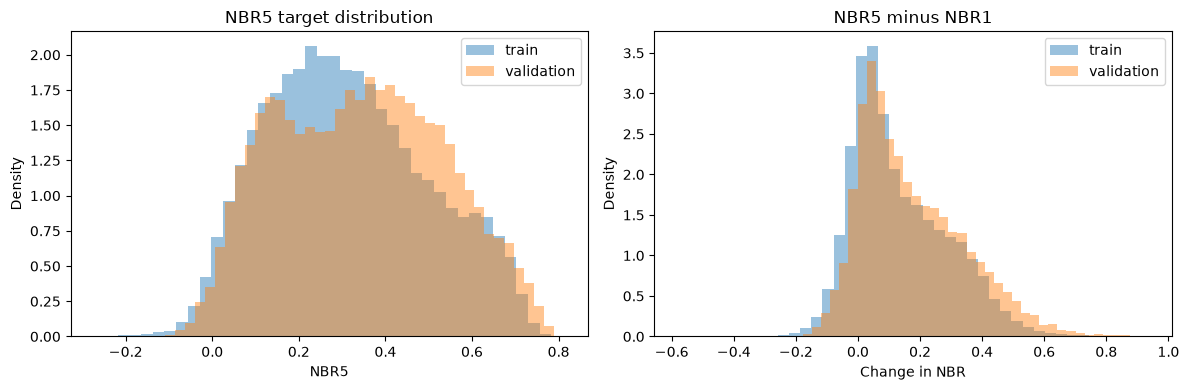

In [26]:

import matplotlib.pyplot as plt

# Use the existing development DataFrame created in Stage 1.
# It contains training/validation targets, never test targets.
dev_target = dev.loc[
    dev["split"].isin(["train", "validation"]),
    ["split", "fire_id", "nbr_5_mean", "nbr_1_mean"]
].copy()

assert set(dev_target["split"].unique()) <= {"train", "validation"}

# Change in vegetation spectral condition from Season 1 to Season 5
dev_target["recovery_change"] = (
    dev_target["nbr_5_mean"] - dev_target["nbr_1_mean"]
)

print("NBR5 TARGET DISTRIBUTION")
display(
    dev_target.groupby("split")["nbr_5_mean"]
    .agg(["count", "mean", "std", "median", "min", "max"])
    .round(3)
)

print("\nCHANGE FROM SEASON 1 TO SEASON 5")
display(
    dev_target.groupby("split")["recovery_change"]
    .agg(["mean", "median", "std", "min", "max"])
    .round(3)
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for split in ["train", "validation"]:
    subset = dev_target.loc[dev_target["split"] == split]

    axes[0].hist(
        subset["nbr_5_mean"].dropna(),
        bins=40, density=True, alpha=0.45, label=split
    )

    axes[1].hist(
        subset["recovery_change"].dropna(),
        bins=40, density=True, alpha=0.45, label=split
    )

axes[0].set_title("NBR5 target distribution")
axes[0].set_xlabel("NBR5")

axes[1].set_title("NBR5 minus NBR1")
axes[1].set_xlabel("Change in NBR")

for ax in axes:
    ax.set_ylabel("Density")
    ax.legend()

plt.tight_layout()
plt.show()


In [27]:

# STEP 3A — Screen ALL 34 predictors against NBR5
# Training data ONLY. No test outcomes or model fitting.

import numpy as np
import pandas as pd

categorical_cols = ["dominant_evt", "ignition_month"]
numeric_cols = [c for c in predictors if c not in categorical_cols]

assert len(numeric_cols) + len(categorical_cols) == len(predictors)
assert all(pd.api.types.is_numeric_dtype(dev[c]) for c in numeric_cols)

train_eda = dev.loc[
    dev["split"].eq("train"),
    list(predictors) + ["nbr_5_mean"]
].copy()

assert len(train_eda) == 61090

# A. Numerical feature screening
results = []

for col in numeric_cols:
    subset = train_eda[[col, "nbr_5_mean"]].dropna()

    results.append({
        "feature": col,
        "valid_rows": len(subset),
        "missing_pct": 100 * train_eda[col].isna().mean(),
        "pearson": subset[col].corr(
            subset["nbr_5_mean"], method="pearson"
        ),
        "spearman": subset[col].rank().corr(
            subset["nbr_5_mean"].rank()
        ),
    })

numeric_screen = pd.DataFrame(results)
numeric_screen = numeric_screen.sort_values(
    "spearman",
    key=lambda s: s.abs(),
    ascending=False
)

print(f"NUMERICAL PREDICTORS: {len(numeric_cols)}")
display(numeric_screen.round(3))

# B. Categorical feature screening
categorical_screens = {}

for col in categorical_cols:
    summary = (
        train_eda.groupby(col, dropna=False)["nbr_5_mean"]
        .agg(["count", "mean", "median", "std"])
        .sort_values("count", ascending=False)
    )

    summary["pct_of_train"] = (
        100 * summary["count"] / len(train_eda)
    )

    categorical_screens[col] = summary

    print(f"\nCATEGORICAL: {col}")
    print(f"Total categories: {len(summary)}")
    display(summary.head(12).round(3))

print("\nScreening complete — no features removed.")


NUMERICAL PREDICTORS: 32


,feature,valid_rows,missing_pct,pearson,spearman
0,nbr_pre_mean,61090,0.000,0.795,0.807
2,tree_cover_mean,61090,0.000,0.731,0.726
18,nbr_1_mean,61090,0.000,0.766,0.699
19,pre_s1_prcp_mm,61090,0.000,0.497,0.460
26,pre_s1_vpd_anom_kpa,61090,0.000,0.424,0.424
30,s1_vpd_anom_kpa,61090,0.000,0.394,0.386
24,pre_s1_tmax_anom_c,61090,0.000,0.423,0.380
3,tree_height_mean,61090,0.000,0.339,0.362
27,s1_prcp_anom_mm,61090,0.000,-0.375,-0.334
25,pre_s1_tmin_anom_c,61090,0.000,0.357,0.291



CATEGORICAL: dominant_evt
Total categories: 44


,count,mean,median,std,pct_of_train
dominant_evt,,,,,
3028,12425,0.339,0.339,0.181,20.339
3027,7602,0.367,0.353,0.176,12.444
3114,7472,0.208,0.198,0.124,12.231
3014,7129,0.335,0.325,0.135,11.670
3029,5962,0.335,0.323,0.156,9.759
3032,3800,0.194,0.187,0.161,6.220
3031,3019,0.126,0.101,0.124,4.942
3043,2786,0.604,0.638,0.108,4.560
3053,1978,0.213,0.191,0.111,3.238



CATEGORICAL: ignition_month
Total categories: 10


,count,mean,median,std,pct_of_train
ignition_month,,,,,
7,26338,0.343,0.337,0.176,43.113
8,14516,0.355,0.341,0.202,23.762
9,7501,0.270,0.268,0.143,12.279
6,6575,0.168,0.149,0.154,10.763
10,2634,0.300,0.271,0.168,4.312
12,2610,0.275,0.271,0.089,4.272
5,447,0.033,0.034,0.033,0.732
4,395,0.590,0.634,0.134,0.647
11,73,0.148,0.133,0.103,0.119



Screening complete — no features removed.


TOP 20 STRONGEST FEATURE PAIRS


,feature_1,feature_2,pearson_r,absolute_r
321,hist_tmax_c,hist_s1_vpd_kpa,0.960,0.960
466,pre_s1_tmax_c,pre_s1_vpd_kpa,0.882,0.882
465,pre_s1_tmax_c,pre_s1_tmin_c,0.873,0.873
2,nbr_pre_mean,tree_cover_mean,0.868,0.868
353,hist_tmin_c,pre_s1_tmin_c,0.827,0.827
382,hist_s1_vpd_kpa,pre_s1_vpd_kpa,0.823,0.823
380,hist_s1_vpd_kpa,pre_s1_tmax_c,0.774,0.774
320,hist_tmax_c,hist_tmin_c,0.765,0.765
303,hist_prcp_mm,s1_prcp_anom_mm,-0.756,0.756
352,hist_tmin_c,pre_s1_tmax_c,0.753,0.753



VERY STRONG PAIRS (absolute correlation >= 0.85)


,feature_1,feature_2,pearson_r,absolute_r
321,hist_tmax_c,hist_s1_vpd_kpa,0.960,0.960
466,pre_s1_tmax_c,pre_s1_vpd_kpa,0.882,0.882
465,pre_s1_tmax_c,pre_s1_tmin_c,0.873,0.873
2,nbr_pre_mean,tree_cover_mean,0.868,0.868


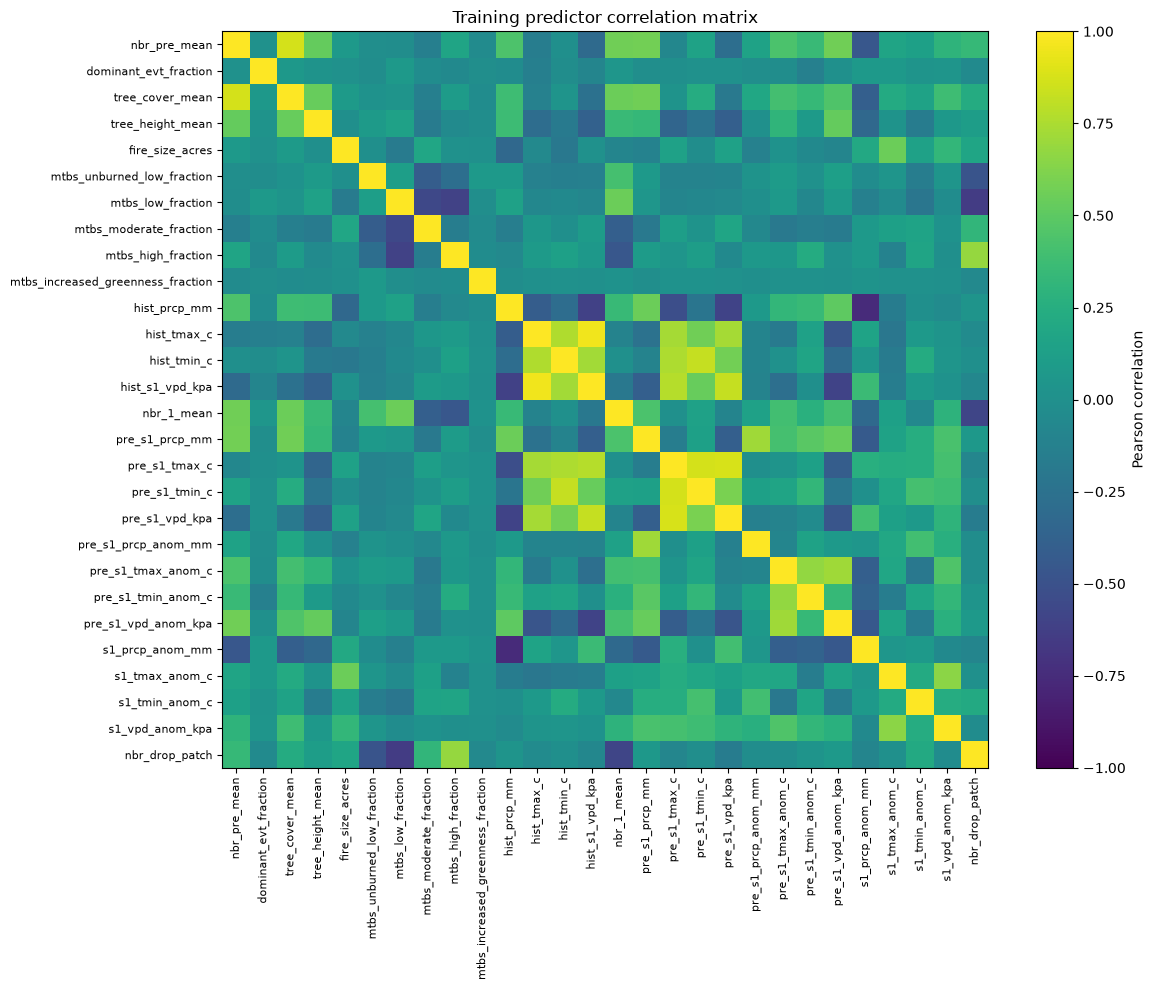

In [28]:

# STEP 3B — Feature vs. feature correlations
# Training data only. Terrain excluded until repaired.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

terrain_cols = {
    "elevation_mean",
    "slope_mean",
    "northness_mean",
    "eastness_mean"
}

num_features = [
    c for c in numeric_cols
    if c not in terrain_cols
]

assert "nbr_5_mean" not in num_features

# Correlation matrix: every numerical predictor vs. every other
corr_matrix = train_eda[num_features].corr(method="pearson")

# Keep each unique pair exactly once
upper_mask = np.triu(
    np.ones(corr_matrix.shape, dtype=bool), k=1
)

pairs = (
    corr_matrix.where(upper_mask)
    .stack()
    .reset_index()
)

pairs.columns = ["feature_1", "feature_2", "pearson_r"]
pairs["absolute_r"] = pairs["pearson_r"].abs()

pairs = pairs.sort_values(
    "absolute_r", ascending=False
)

print("TOP 20 STRONGEST FEATURE PAIRS")
display(pairs.head(20).round(3))

print("\nVERY STRONG PAIRS (absolute correlation >= 0.85)")
display(
    pairs.loc[pairs["absolute_r"] >= 0.85]
    .round(3)
)

# Full correlation heatmap
fig, ax = plt.subplots(figsize=(12, 10))

im = ax.imshow(
    corr_matrix,
    vmin=-1,
    vmax=1,
    aspect="auto"
)

ax.set_xticks(range(len(num_features)))
ax.set_yticks(range(len(num_features)))

ax.set_xticklabels(num_features, rotation=90, fontsize=8)
ax.set_yticklabels(num_features, fontsize=8)

ax.set_title("Training predictor correlation matrix")

fig.colorbar(im, ax=ax, label="Pearson correlation")
plt.tight_layout()
plt.show()


In [29]:

# PHASE 4 — VPD vs NBR5: overall, between-fire, within-fire
# Training data only. No test labels.

import pandas as pd

feature = "pre_s1_vpd_anom_kpa"
target_col = "nbr_5_mean"

df = dev.loc[
    dev["split"].eq("train"),
    ["fire_id", feature, target_col]
].dropna().copy()

# 1. Overall correlation across all training patches
overall_r = df[feature].corr(df[target_col])

# 2. Between-fire correlation (one mean per fire)
fire_means = df.groupby("fire_id")[
    [feature, target_col]
].mean()

between_r = fire_means[feature].corr(
    fire_means[target_col]
)

# 3. Within-fire correlation:
# Subtract each fire's mean from its patch values.
df["vpd_within"] = (
    df[feature]
    - df.groupby("fire_id")[feature].transform("mean")
)

df["nbr5_within"] = (
    df[target_col]
    - df.groupby("fire_id")[target_col].transform("mean")
)

within_r = df["vpd_within"].corr(df["nbr5_within"])

# Summary
display(pd.DataFrame({
    "Comparison": [
        "Overall (all patches)",
        "Between fires (fire averages)",
        "Within fires (demeaned patches)"
    ],
    "Pearson r": [overall_r, between_r, within_r]
}).round(3))

# Check whether VPD varies enough within fires
within_std = df.groupby("fire_id")[feature].std()

print("Training patches:", len(df))
print("Training fires:", df["fire_id"].nunique())
print("Median within-fire VPD std:", round(within_std.median(), 4))
print("Fires with near-zero within-fire VPD variation:",
      int(within_std.fillna(0).lt(1e-8).sum()))


,Comparison,Pearson r
0,Overall (all patches),0.424
1,Between fires (fire averages),0.584
2,Within fires (demeaned patches),0.099


Training patches: 61090
Training fires: 78
Median within-fire VPD std: 0.0047
Fires with near-zero within-fire VPD variation: 3



HIGH BURN SEVERITY VS NBR5


,severity_bin,prefire_group,mean,count
0,0,Higher pre-fire NBR,0.506,16833
1,0,Lower pre-fire NBR,0.187,20610
2,"(0, .25]",Higher pre-fire NBR,0.408,4597
3,"(0, .25]",Lower pre-fire NBR,0.187,4690
4,"(.25, .50]",Higher pre-fire NBR,0.354,2408
5,"(.25, .50]",Lower pre-fire NBR,0.183,2018
6,"(.50, .75]",Higher pre-fire NBR,0.317,2065
7,"(.50, .75]",Lower pre-fire NBR,0.179,1303
8,"(.75, 1]",Higher pre-fire NBR,0.310,4642
9,"(.75, 1]",Lower pre-fire NBR,0.213,1924



NBR DROP VS NBR5


,drop_bin,prefire_group,mean,count
0,"(-0.297, 0.0895]",Higher pre-fire NBR,0.618,3070
1,"(-0.297, 0.0895]",Lower pre-fire NBR,0.175,7112
2,"(0.0895, 0.167]",Higher pre-fire NBR,0.553,5385
3,"(0.0895, 0.167]",Lower pre-fire NBR,0.189,4797
4,"(0.167, 0.256]",Higher pre-fire NBR,0.484,4936
5,"(0.167, 0.256]",Lower pre-fire NBR,0.170,5245
6,"(0.256, 0.368]",Higher pre-fire NBR,0.423,4371
7,"(0.256, 0.368]",Lower pre-fire NBR,0.182,5811
8,"(0.368, 0.505]",Higher pre-fire NBR,0.368,4684
9,"(0.368, 0.505]",Lower pre-fire NBR,0.224,5497


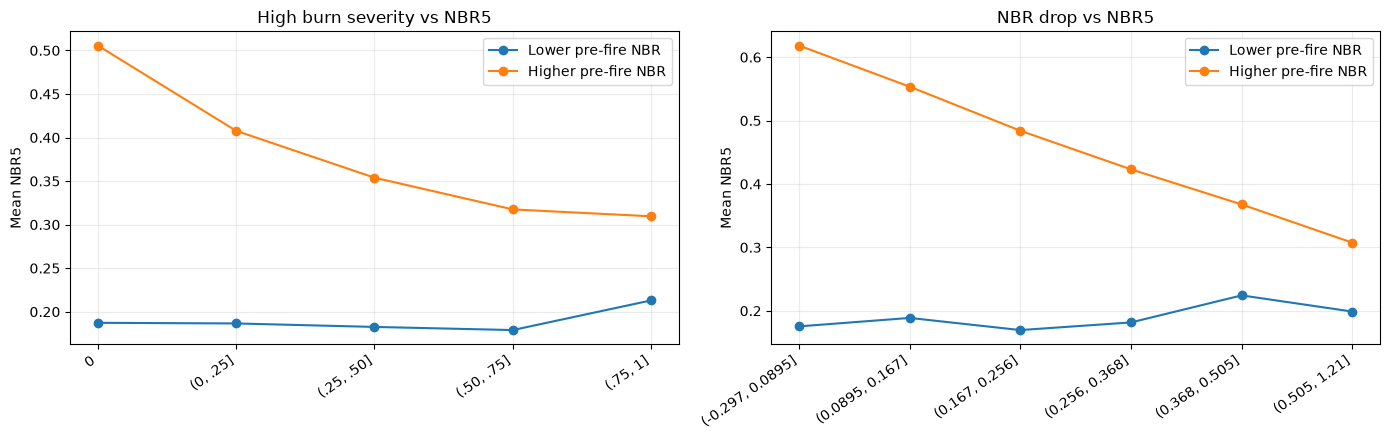

Training rows: 61090
Pre-fire NBR median: 0.495


In [30]:

# STEP 4 — Nonlinear / conditional relationships
# Training data only. No test target.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

cols = [
    "nbr_pre_mean",
    "nbr_5_mean",
    "mtbs_high_fraction",
    "nbr_drop_patch"
]

df = dev.loc[dev["split"].eq("train"), cols].dropna().copy()

# Split patches by pre-fire NBR
cutoff = df["nbr_pre_mean"].median()

df["prefire_group"] = np.where(
    df["nbr_pre_mean"] >= cutoff,
    "Higher pre-fire NBR",
    "Lower pre-fire NBR"
)

# Fixed bins for high-severity fraction
df["severity_bin"] = pd.cut(
    df["mtbs_high_fraction"],
    bins=[-0.001, 0, 0.25, 0.50, 0.75, 1.001],
    labels=["0", "(0, .25]", "(.25, .50]",
            "(.50, .75]", "(.75, 1]"]
)

# Quantile bins for NBR drop
df["drop_bin"] = pd.qcut(
    df["nbr_drop_patch"],
    q=6,
    duplicates="drop"
)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

for ax, bin_col, title in [
    (axes[0], "severity_bin", "High burn severity vs NBR5"),
    (axes[1], "drop_bin", "NBR drop vs NBR5")
]:
    summary = (
        df.groupby([bin_col, "prefire_group"], observed=True)
          ["nbr_5_mean"]
          .agg(["mean", "count"])
          .reset_index()
    )

    labels = list(df[bin_col].cat.categories)

    for group in ["Lower pre-fire NBR", "Higher pre-fire NBR"]:
        subset = summary.loc[summary["prefire_group"].eq(group)]
        means = subset.set_index(bin_col)["mean"].reindex(labels)

        ax.plot(
            range(len(labels)),
            means,
            marker="o",
            label=group
        )

    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(
        [str(x) for x in labels],
        rotation=35,
        ha="right"
    )
    ax.set_ylabel("Mean NBR5")
    ax.set_title(title)
    ax.legend()
    ax.grid(alpha=0.25)

    print(f"\n{title.upper()}")
    display(summary.round(3))

plt.tight_layout()
plt.show()

print("Training rows:", len(df))
print("Pre-fire NBR median:", round(cutoff, 3))


In [31]:

import pandas as pd
from pathlib import Path

root = Path.cwd()
if not (root / "data/processed").exists():
    root = root.parent

terrain = [
    "elevation_mean",
    "slope_mean",
    "northness_mean",
    "eastness_mean"
]

keys = ["fire_id", "patch_id"]
cols = keys + ["split"] + terrain

old = pd.read_parquet(
    root / "data/processed/patch_model_eligible_v1.parquet",
    columns=cols
).set_index(keys).sort_index()

new = pd.read_parquet(
    root / "data/processed/patch_model_eligible_terrain_v2.parquet",
    columns=cols
).set_index(keys).sort_index()

assert len(old) == len(new) == 111257
assert old.index.is_unique and new.index.is_unique
assert old.index.equals(new.index)
assert old["split"].equals(new["split"])

# Missingness before vs after correction
old_missing = old.groupby("split")[terrain].apply(
    lambda x: x.isna().mean() * 100
)
new_missing = new.groupby("split")[terrain].apply(
    lambda x: x.isna().mean() * 100
)

print("MISSINGNESS BY SPLIT (%)")
display(pd.concat(
    [
        old_missing.stack().rename("Before (%)"),
        new_missing.stack().rename("After (%)")
    ],
    axis=1
).round(3))

# Recovery and data loss
print("\nRECOVERY SUMMARY")
display(pd.DataFrame({
    "Previously missing": old[terrain].isna().sum(),
    "Recovered": (
        old[terrain].isna() & new[terrain].notna()
    ).sum(),
    "Still missing": new[terrain].isna().sum(),
    "Previously valid lost": (
        old[terrain].notna() & new[terrain].isna()
    ).sum()
}))

# Corrected terrain value ranges
print("\nCORRECTED TERRAIN DISTRIBUTIONS")
display(
    new[terrain].describe().T[
        ["mean", "std", "min", "25%", "50%", "75%", "max"]
    ].round(3)
)


MISSINGNESS BY SPLIT (%)


Before (%)  After (%)
split                                           
test       elevation_mean      31.295        0.0
           slope_mean          31.317        0.0
           northness_mean      31.317        0.0
           eastness_mean       31.317        0.0
train      elevation_mean      10.311        0.0
           slope_mean          10.327        0.0
           northness_mean      10.327        0.0
           eastness_mean       10.327        0.0
validation elevation_mean       0.547        0.0
           slope_mean           0.562        0.0
           northness_mean       0.562        0.0
           eastness_mean        0.562        0.0


RECOVERY SUMMARY


,Previously missing,Recovered,Still missing,Previously valid lost
elevation_mean,15984,15984,0,0
slope_mean,16004,16004,0,0
northness_mean,16004,16004,0,0
eastness_mean,16004,16004,0,0



CORRECTED TERRAIN DISTRIBUTIONS


,mean,std,min,25%,50%,75%,max
elevation_mean,1255.469,708.895,38.415,648.194,1214.864,1791.170,3091.014
slope_mean,22.274,9.492,0.000,15.121,22.701,29.593,59.457
northness_mean,0.078,0.605,-1.000,-0.459,0.129,0.637,1.000
eastness_mean,-0.098,0.614,-1.000,-0.663,-0.162,0.448,1.000


In [32]:

# STEP 2 — Corrected terrain distributions and target relationships

terrain_df = new.reset_index()

print("TERRAIN MEANS BY SPLIT")
display(
    terrain_df.groupby("split")[terrain]
    .mean()
    .reindex(["train", "validation", "test"])
    .T.round(3)
)

print("\nEQUAL-FIRE-WEIGHTED TERRAIN MEANS")
display(
    terrain_df.groupby(["split", "fire_id"])[terrain]
    .mean()
    .groupby("split")
    .mean()
    .reindex(["train", "validation", "test"])
    .T.round(3)
)

# Join corrected inputs to training labels only
train_terrain = (
    dev.loc[
        dev["split"].eq("train"),
        ["fire_id", "patch_id", "nbr_5_mean",
         "nbr_pre_mean", "tree_cover_mean"]
    ]
    .join(new[terrain], on=["fire_id", "patch_id"],
          validate="one_to_one")
)

assert len(train_terrain) == 61090
assert train_terrain[terrain].notna().all().all()

results = []

for col in terrain:
    x = train_terrain[col]
    y = train_terrain["nbr_5_mean"]

    results.append({
        "feature": col,
        "pearson": x.corr(y),
        "spearman": x.rank().corr(y.rank()),
        "corr_with_NBRpre": x.corr(train_terrain["nbr_pre_mean"]),
        "corr_with_tree_cover": x.corr(train_terrain["tree_cover_mean"])
    })

print("\nTERRAIN CORRELATIONS — TRAINING ONLY")
display(pd.DataFrame(results).set_index("feature").round(3))

print("\nCORRELATIONS AMONG TERRAIN VARIABLES")
display(train_terrain[terrain].corr().round(3))


TERRAIN MEANS BY SPLIT


split,train,validation,test
elevation_mean,1252.188,1362.022,1193.918
slope_mean,22.788,21.738,21.588
northness_mean,0.071,0.151,0.046
eastness_mean,-0.085,-0.144,-0.094



EQUAL-FIRE-WEIGHTED TERRAIN MEANS


split,train,validation,test
elevation_mean,1064.118,1086.573,1059.962
slope_mean,21.458,19.002,19.789
northness_mean,0.138,0.102,0.189
eastness_mean,-0.040,-0.069,-0.104



TERRAIN CORRELATIONS — TRAINING ONLY


,pearson,spearman,corr_with_NBRpre,corr_with_tree_cover
feature,,,,
elevation_mean,-0.288,-0.230,-0.152,-0.245
slope_mean,0.229,0.239,0.201,0.248
northness_mean,0.068,0.070,0.006,0.053
eastness_mean,-0.025,-0.026,-0.029,-0.004



CORRELATIONS AMONG TERRAIN VARIABLES


,elevation_mean,slope_mean,northness_mean,eastness_mean
elevation_mean,1.000,-0.126,-0.101,-0.019
slope_mean,-0.126,1.000,0.055,-0.011
northness_mean,-0.101,0.055,1.000,0.071
eastness_mean,-0.019,-0.011,0.071,1.000
